# Pseudotime Trajectory Inference

## Imports

In [1]:
import anndata as ad
import anndata2ri
import numpy as np
import pandas as pd
import scanpy as sc
from rpy2.robjects.packages import importr

%load_ext rpy2.ipython
anndata2ri.set_ipython_converter()

In [2]:
%%R
library(SingleCellExperiment)
library(slingshot)
library(RaceID)

cat("R OK\n")
sessionInfo()

R OK
R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Pop!_OS 22.04 LTS

Matrix products: default
BLAS/LAPACK: /home/jasiek/anaconda3/envs/scrna-ti/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=pl_PL.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=pl_PL.UTF-8        LC_COLLATE=pl_PL.UTF-8    
 [5] LC_MONETARY=pl_PL.UTF-8    LC_MESSAGES=pl_PL.UTF-8   
 [7] LC_PAPER=pl_PL.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=pl_PL.UTF-8 LC_IDENTIFICATION=C       

time zone: Europe/Warsaw
tzcode source: system (glibc)

attached base packages:
[1] stats4    tools     stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] RaceID_0.4.2                slingshot_2.14.0           
 [3] TrajectoryUtils_1.14.0      princurve_2.1.6            
 [5] SingleCellExperiment_1.28.0 SummarizedExperiment_1.36.0
 [7] Biobase_2.66.0  

Ładowanie wymaganego pakietu: SummarizedExperiment
Ładowanie wymaganego pakietu: MatrixGenerics
Ładowanie wymaganego pakietu: matrixStats

Dołączanie pakietu: ‘MatrixGenerics’

Następujące obiekty zostały zakryte z ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, 

### Data Loading

In [3]:
adata = sc.read("merged_dataset.h5ad")
adata

AnnData object with n_obs × n_vars = 14915 × 28692
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt'

## Common preprocessing

In [4]:
# Metadata from Cell Annotation (+ optional Hérault paper columns for Layer B)
meta = pd.read_csv("cell_annotation_metadata.tsv", sep="\t", index_col=0)
assert meta.index.equals(adata.obs_names) or meta.index.isin(adata.obs_names).all()
adata.obs = adata.obs.join(meta[["label", "label_color", "leiden", "discard"]], how="left")

batch_to_sample = {
    "young_A": "young_A",
    "young_B": "young_B",
    "old_A": "aged_A",
    "old_B": "aged_B",
}
_barcode = pd.Index(adata.obs_names).str.replace(r"_\d+$", "", regex=True)
_sample = adata.obs["batch"].astype(str).map(batch_to_sample)
_paper_key = pd.Index(_sample.to_numpy() + "_" + _barcode.to_numpy())

paper = pd.read_csv(
    "sc_metadata.csv",
    usecols=["barcode", "sampleName", "HSPC_state", "Pseudotime", "hscScore", "Monocle_state"],
)
paper = paper.assign(paper_key=paper["sampleName"].astype(str) + "_" + paper["barcode"].astype(str))
paper = paper.drop_duplicates("paper_key").set_index("paper_key")
paper_aligned = paper.reindex(_paper_key)
paper_aligned.index = adata.obs_names
adata.obs["paper_state"] = paper_aligned["HSPC_state"].values
adata.obs["paper_pseudotime"] = paper_aligned["Pseudotime"].values
adata.obs["hscScore"] = paper_aligned["hscScore"].values
adata.obs["monocle_state"] = paper_aligned["Monocle_state"].values

n_before = adata.n_obs
adata = adata[~adata.obs["discard"].fillna(False).astype(bool)].copy()
print(f"Dropped discard=True: {n_before - adata.n_obs} cells → {adata.n_obs} left")
print("labels:", adata.obs["label"].value_counts().to_dict())
print("paper_state:", adata.obs["paper_state"].value_counts(dropna=False).head(12).to_dict())

Dropped discard=True: 815 cells → 14100 left
labels: {'preDiff': 9038, 'ifnHSC': 3294, 'qHSC': 1321, 'pEr': 447}
paper_state: {nan: 8778, 'preDiff': 2432, 'iHSC': 1068, 'qHSC': 671, 'ifnHSC': 452, 'pMk': 272, 'pEr': 272, 'pLymph': 75, 'srHSC': 71, 'pNeuMast': 9}


### Layer A — biological priors from labels

Recycled from `markers.py` / annotation metadata (no marker-score medoid).
`root_state`, `terminal_states`, `transient_states` come from the Hérault state hierarchy;
grouping uses `label` (`cell_type`).

In [5]:
from markers import states_and_markers

ROOT_CANDIDATES = ("iHSC", "qHSC")  # initial / quiescent; prefer iHSC
TERMINAL_STATES = ("pEr", "pMk", "pLymph", "pNeuMast")
TRANSIENT_STATES = ("srHSC", "ifnHSC", "qHSC", "preDiff")

adata.obs["cell_type"] = adata.obs["label"].astype("category")
adata.obs["label"] = adata.obs["cell_type"]

present = set(adata.obs["label"].dropna().astype(str).unique())
root_state = next((s for s in ROOT_CANDIDATES if s in present), None)
if root_state is None:
    raise ValueError(f"No root candidate in labels {sorted(present)}; tried {ROOT_CANDIDATES}")

terminal_states = [s for s in TERMINAL_STATES if s in present]
transient_states = [s for s in TRANSIENT_STATES if s in present and s != root_state]

# Paper taxonomy (full Hérault set) — useful when annotation collapsed terminals
paper_present = set(adata.obs["paper_state"].dropna().astype(str).unique())
paper_root_state = next((s for s in ROOT_CANDIDATES if s in paper_present), None)
paper_terminals = [s for s in TERMINAL_STATES if s in paper_present]

adata.uns["root_state"] = root_state
adata.uns["terminal_states"] = terminal_states
adata.uns["transient_states"] = transient_states
adata.uns["ti_priors"] = {
    "layer": "A",
    "root_state": root_state,
    "terminal_states": terminal_states,
    "transient_states": transient_states,
    "root_candidates": list(ROOT_CANDIDATES),
    "states_and_markers_keys": list(states_and_markers),
    "paper_root_state": paper_root_state,
    "paper_terminal_states": paper_terminals,
}

print("root_state:", root_state, f"(n={int((adata.obs['label'] == root_state).sum())})")
print("terminal_states:", terminal_states)
print("transient_states:", transient_states)
print("paper_root_state:", paper_root_state, "| paper_terminals:", paper_terminals)
adata.uns["ti_priors"]

root_state: qHSC (n=1321)
terminal_states: ['pEr']
transient_states: ['ifnHSC', 'preDiff']
paper_root_state: iHSC | paper_terminals: ['pEr', 'pMk', 'pLymph', 'pNeuMast']


{'layer': 'A',
 'root_state': 'qHSC',
 'terminal_states': ['pEr'],
 'transient_states': ['ifnHSC', 'preDiff'],
 'root_candidates': ['iHSC', 'qHSC'],
 'states_and_markers_keys': ['iHSC',
  'srHSC',
  'ifnHSC',
  'qHSC',
  'preDiff',
  'pLymph',
  'pNeuMast',
  'pEr',
  'pMk'],
 'paper_root_state': 'iHSC',
 'paper_terminal_states': ['pEr', 'pMk', 'pLymph', 'pNeuMast']}

### Layer B — root cell for APIs that need it (DPT `iroot`, etc.)

1. Prefer medoid of `root_state` cells in integrated embedding (`X_emb` → `X_pca`, else existing `X_pca`).
2. If no embedding yet: use paper `hscScore` (argmax) / `paper_pseudotime` (argmin) within `root_state`.
3. Store `uns['root_cell']` and integer `uns['iroot']` for scanpy.

In [6]:
from scipy.spatial.distance import cdist

root_mask = adata.obs["label"].astype(str) == adata.uns["root_state"]
root_idx = np.where(root_mask.to_numpy())[0]
if root_idx.size == 0:
    raise ValueError(f"No cells with label == {adata.uns['root_state']!r}")

# Embedding for medoid (plan: X_emb copied to X_pca for anndata2ri / Slingshot)
if "X_emb" in adata.obsm:
    adata.obsm["X_pca"] = np.asarray(adata.obsm["X_emb"])
emb_key = "X_pca" if "X_pca" in adata.obsm else None

root_cell = None
root_method = None

if emb_key is not None:
    coords = np.asarray(adata.obsm[emb_key])[root_idx]
    centroid = coords.mean(axis=0, keepdims=True)
    medoid_local = int(cdist(coords, centroid).argmin())
    root_cell = adata.obs_names[root_idx[medoid_local]]
    root_method = f"medoid:{emb_key}"
else:
    sub = adata.obs.loc[root_mask, ["hscScore", "paper_pseudotime"]].copy()
    if sub["hscScore"].notna().any():
        root_cell = sub["hscScore"].astype(float).idxmax()
        root_method = "argmax:hscScore"
    elif sub["paper_pseudotime"].notna().any():
        root_cell = sub["paper_pseudotime"].astype(float).idxmin()
        root_method = "argmin:paper_pseudotime"
    else:
        root_cell = adata.obs_names[root_idx[0]]
        root_method = "fallback:first_root_cell"
        print("WARNING: no embedding and no paper scores; using first root cell")

iroot = int(adata.obs_names.get_loc(root_cell))
adata.uns["root_cell"] = root_cell
adata.uns["iroot"] = iroot
adata.uns["ti_priors_B"] = {
    "layer": "B",
    "root_cell": root_cell,
    "iroot": iroot,
    "method": root_method,
    "n_root_cells": int(root_idx.size),
    "embedding_key": emb_key,
}

# Convenience aliases for later adapters
start_cluster = adata.uns["root_state"]
start_id = root_cell
end_clusters = list(adata.uns["terminal_states"])

print(f"root_cell={root_cell!r}  iroot={iroot}  via {root_method}")
print(f"start_cluster={start_cluster!r}  end_clusters={end_clusters}")
if root_cell in adata.obs.index:
    print(adata.obs.loc[root_cell, ["label", "paper_state", "hscScore", "paper_pseudotime"]])
adata.uns["ti_priors_B"]

root_cell='ATGTGTGGTCCGAGTC-1_2'  iroot=7471  via argmax:hscScore
start_cluster='qHSC'  end_clusters=['pEr']
label                   qHSC
paper_state              NaN
hscScore            0.586932
paper_pseudotime    2.889326
Name: ATGTGTGGTCCGAGTC-1_2, dtype: object


{'layer': 'B',
 'root_cell': 'ATGTGTGGTCCGAGTC-1_2',
 'iroot': 7471,
 'method': 'argmax:hscScore',
 'n_root_cells': 1321,
 'embedding_key': None}

## Inference

### PAGA

In [7]:
# PAGA + DPT (jak tests/test_ti_methods_smoke.py), z iroot z Layer B
if "X_emb" in adata.obsm and "X_pca" not in adata.obsm:
    adata.obsm["X_pca"] = np.asarray(adata.obsm["X_emb"])
if "X_pca" not in adata.obsm:
    sc.pp.pca(adata, n_comps=50)

sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca")
sc.tl.paga(adata, groups="label")
# adata.uns["iroot"] already set in Layer B
sc.tl.diffmap(adata)
sc.tl.dpt(adata)

adata.obs["pseudotime"] = adata.obs["dpt_pseudotime"]
adata.obs["branch"] = adata.obs["label"].astype("category")
print("dpt_pseudotime:", adata.obs["dpt_pseudotime"].describe()[["min", "50%", "max"]].to_dict())
adata.obs[["label", "dpt_pseudotime"]].groupby("label", observed=True)["dpt_pseudotime"].median().sort_values()

dpt_pseudotime: {'min': 0.0, '50%': 0.11578433215618134, 'max': 1.0}


label
qHSC       0.038598
preDiff    0.113611
pEr        0.122611
ifnHSC     0.134229
Name: dpt_pseudotime, dtype: float32

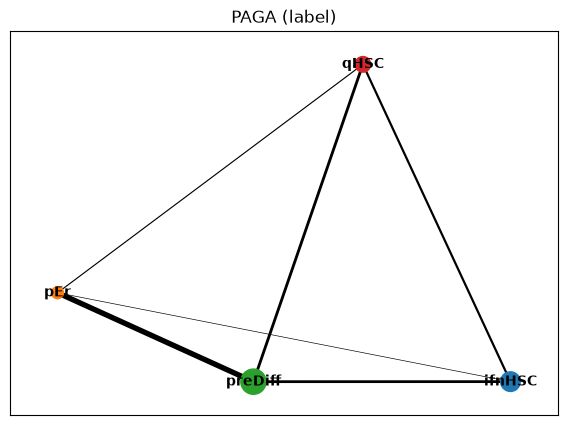

In [8]:
# quick peek; full figures in Results analysis
sc.pl.paga(adata, color="label", title="PAGA (label)", show=True)


## Results analysis

Wizualizacje **bez pełnego STREAM** (scanpy / matplotlib / networkx + `plot_streamlike`):

| STREAM | Tutaj |
|---|---|
| `plot_dimension_reduction` (label) | UMAP: `label`, `pseudotime`, `branch` |
| embedding + markery | UMAP z markerami z `states_and_markers` |
| graf na embeddingu | PAGA (+ PAGA na UMAP) |
| flat tree (topologia) | graf stanów z medianą `pseudotime` |
| KDE + Q1/Q3 | KDE `pseudotime` |
| stream / subway | `plot_streamlike` (`src/utils/plot_streamlike.py`) |

Bez QC (`plot_qc`). Figury → `results/{method}/figures/`.


In [9]:
from pathlib import Path
import matplotlib.pyplot as plt

METHOD = "paga_dpt"
FIGURES_DIR = Path("results") / METHOD / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ensure embedding + contract aliases
if "X_umap" not in adata.obsm:
    sc.tl.umap(adata)
adata.obsm["X_plot"] = np.asarray(adata.obsm["X_umap"])
if "pseudotime" not in adata.obs and "dpt_pseudotime" in adata.obs:
    adata.obs["pseudotime"] = adata.obs["dpt_pseudotime"]
if "branch" not in adata.obs:
    adata.obs["branch"] = adata.obs["label"].astype("category")

print("FIGURES_DIR =", FIGURES_DIR.resolve())


FIGURES_DIR = /home/jasiek/Dokumenty/ideas/scRNAseq-pipeline/results/paga_dpt/figures


### Embedding (UMAP) — label / pseudotime / branch


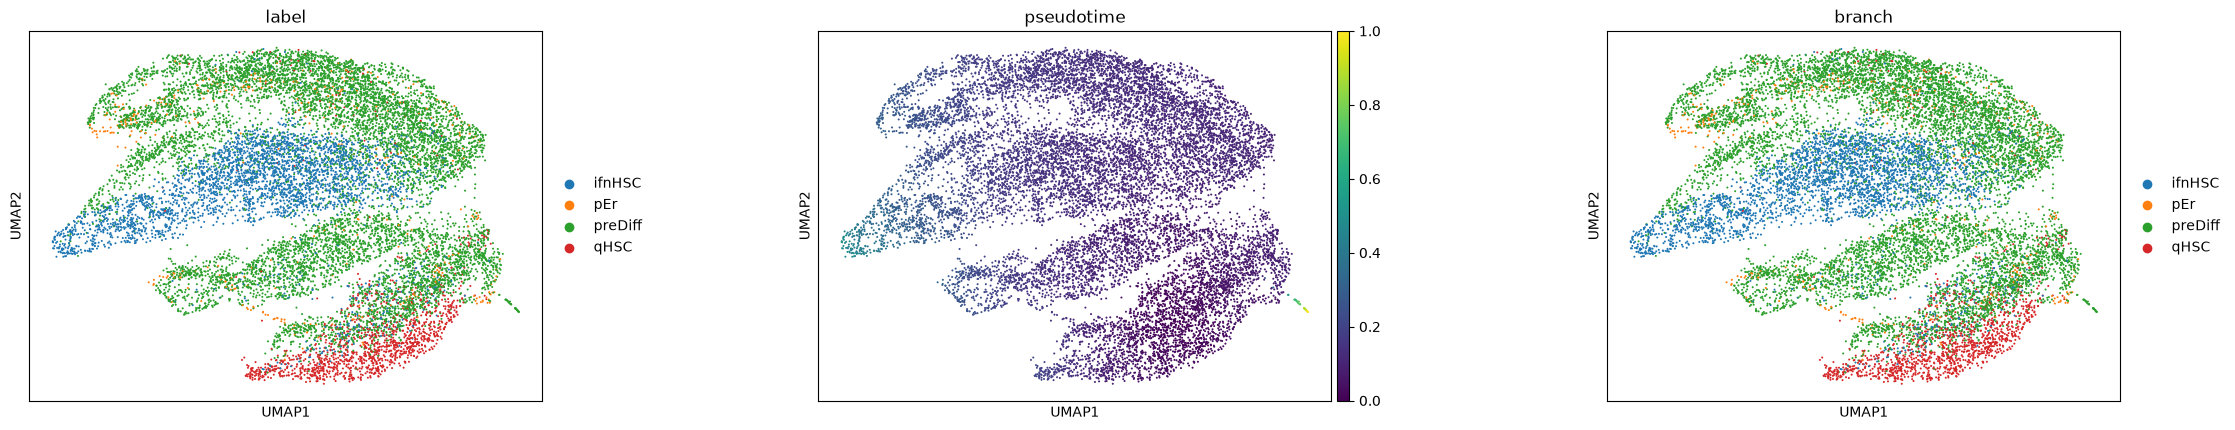

In [10]:
sc.settings.figdir = str(FIGURES_DIR)
sc.pl.umap(
    adata,
    color=["label", "pseudotime", "branch"],
    wspace=0.4,
    show=True,
    save="_label_pseudotime_branch.png",
)
plt.show()


### Embedding + markery fenotypowe

Jak w STREAM (`plot_dimension_reduction` z markerami Cones/NB1) — tu markery z `states_and_markers` obecne w `adata.var_names`.


plotting markers: ['Egr1', 'Fli1', 'Gata2', 'Junb', 'Tal1', 'Gata1', 'Klf1', 'Zfpm1']


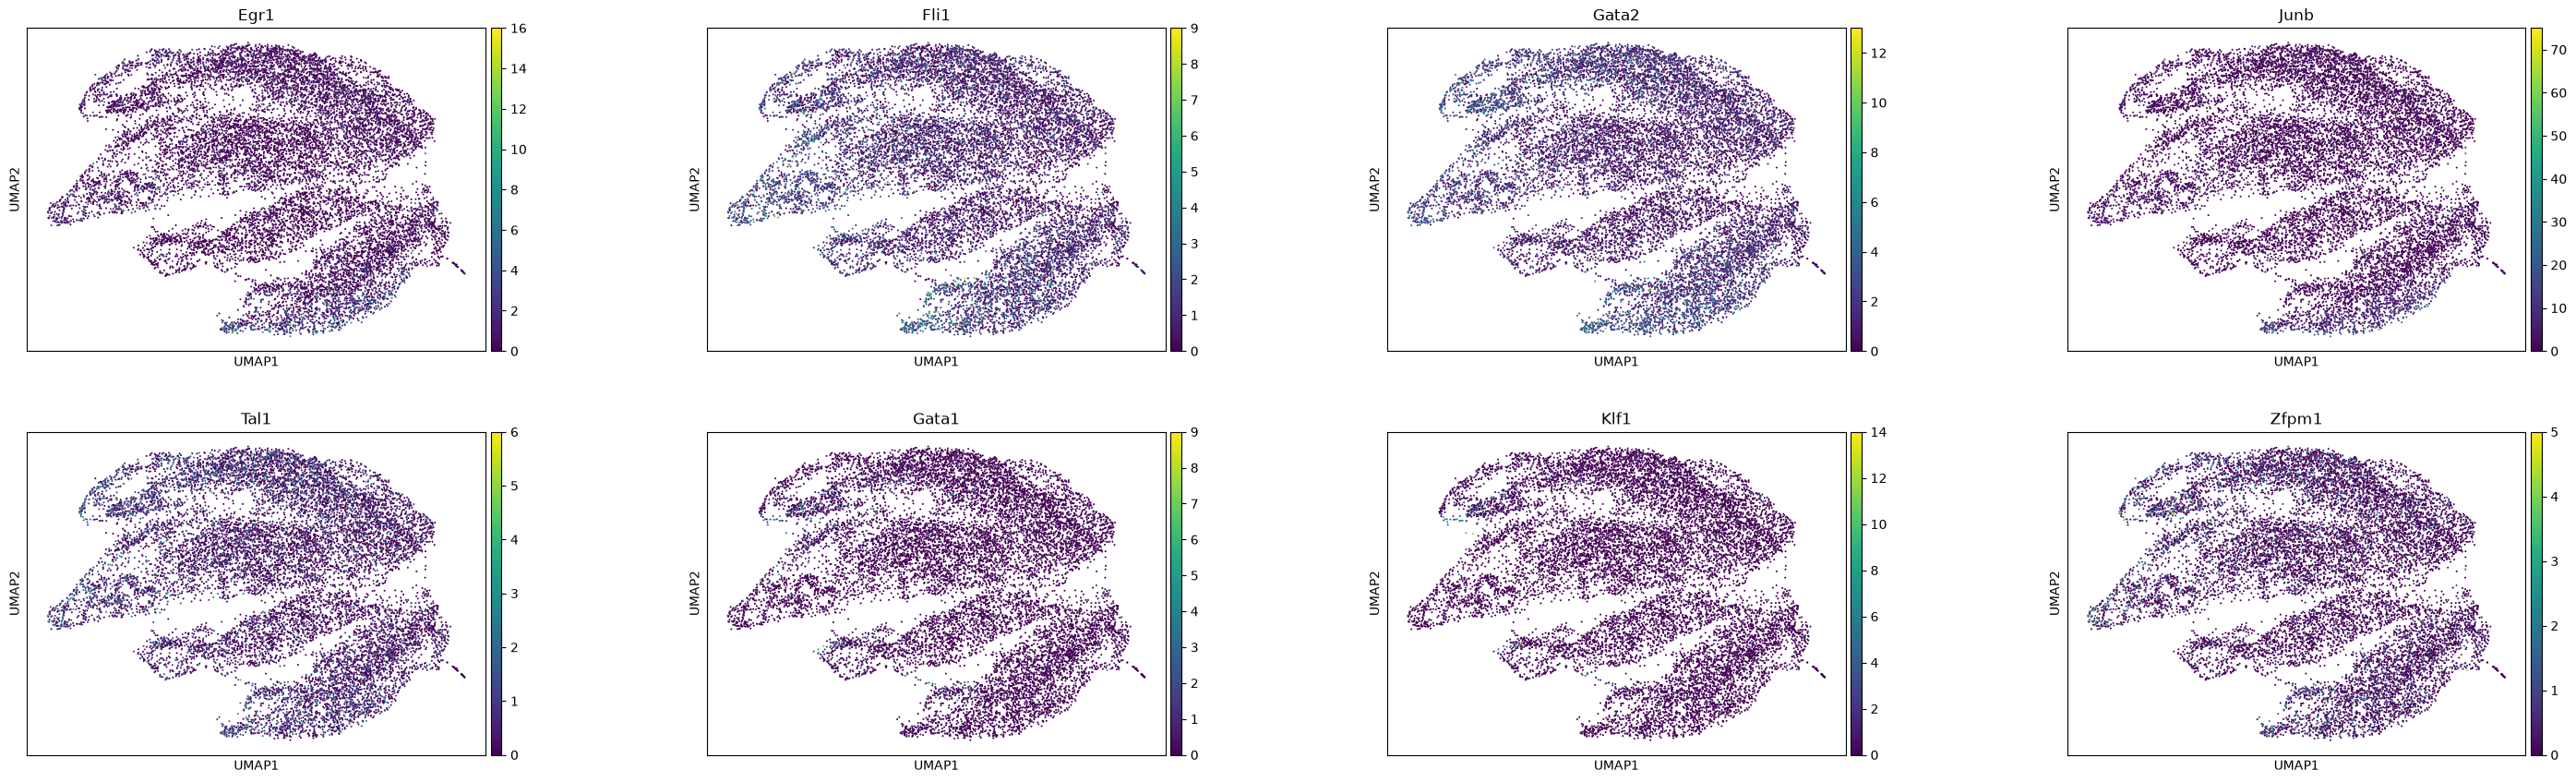

In [11]:
from markers import states_and_markers

sc.settings.figdir = str(FIGURES_DIR)

_marker_priority = []
for _state in [
    adata.uns.get("root_state"),
    *adata.uns.get("terminal_states", []),
    *adata.uns.get("transient_states", []),
]:
    if _state and _state in states_and_markers:
        _marker_priority.extend(sorted(states_and_markers[_state]))

_marker_genes = [g for g in dict.fromkeys(_marker_priority) if g in adata.var_names]
_plot_genes = _marker_genes[:8]
if not _plot_genes:
    print("No marker genes from states_and_markers found in var_names; skip")
else:
    print("plotting markers:", _plot_genes)
    sc.pl.umap(
        adata,
        color=_plot_genes,
        wspace=0.35,
        ncols=4,
        show=True,
        save="_markers.png",
    )
    plt.show()


### Graf trajektorii — PAGA (+ nakładka na UMAP)


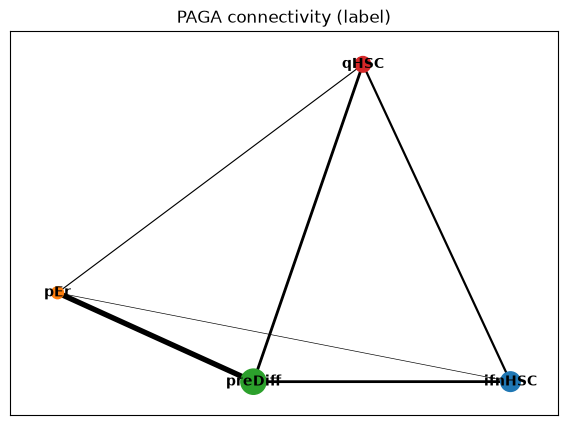

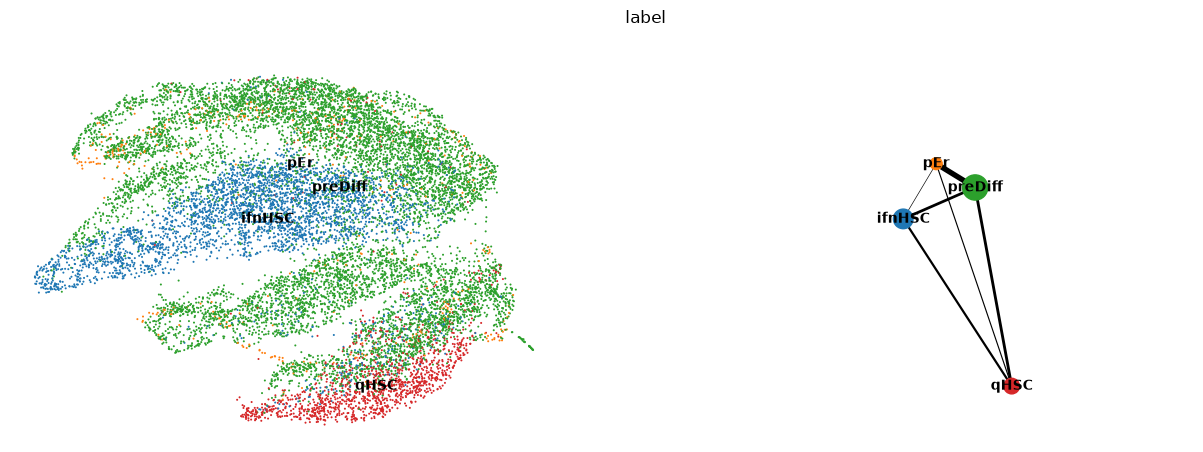

saved under results/paga_dpt/figures


In [12]:
sc.settings.figdir = str(FIGURES_DIR)

# abstract PAGA graph
sc.pl.paga(
    adata,
    color="label",
    title="PAGA connectivity (label)",
    show=True,
    save="_connectivity.png",
)
plt.show()

# PAGA positioned on UMAP
sc.pl.paga_compare(
    adata,
    basis="umap",
    color="label",
    frameon=False,
    show=True,
    save="_umap.png",
)
plt.show()
print("saved under", FIGURES_DIR)


### Flat-tree–like — stany vs mediana pseudoczasu

Uproszczony odpowiednik `plot_flat_tree`: węzły = `label`, pozycja x = mediana `pseudotime`,
krawędzie z realnej topologii PAGA (`connectivities_tree`, `src/utils/trajectory_graph.py`)
— nie z rankingu po medianie pseudoczasu (fallback tylko gdy PAGA niedostępne).


state graph topology source: paga


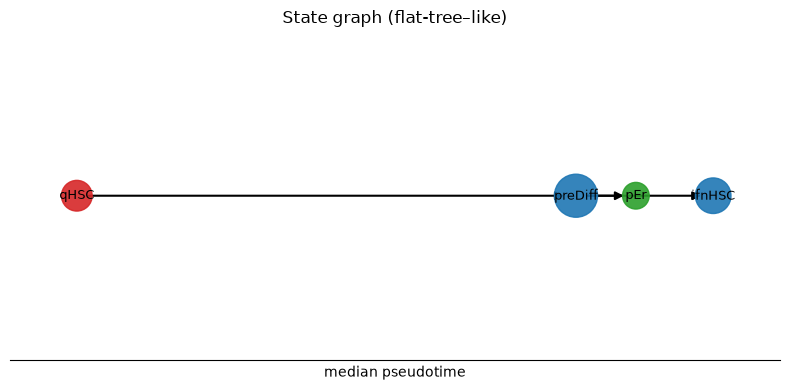

edges: [('qHSC', 'preDiff'), ('preDiff', 'ifnHSC'), ('preDiff', 'pEr')]


In [13]:
import networkx as nx

from src.utils.trajectory_graph import derive_trajectory_graph

pt_key = "pseudotime"
med = (
    adata.obs.groupby("label", observed=True)[pt_key]
    .median()
    .astype(float)
    .sort_values()
)
counts = adata.obs["label"].astype(str).value_counts()

terminals = set(map(str, adata.uns.get("terminal_states", [])))
root = str(adata.uns.get("root_state"))
states = [str(s) for s in med.index]

# real topology: PAGA connectivity tree (fallback: median-pt chain if no PAGA)
tree, root, edge_source = derive_trajectory_graph(
    adata,
    root=root,
    state_key="label",
    pt_key=pt_key,
    terminal_states=adata.uns.get("terminal_states"),
)
edges = list(tree.edges())
print(f"state graph topology source: {edge_source}")

G = nx.DiGraph()
G.add_nodes_from(states)
G.add_edges_from(edges)

pos = {s: (float(med[s]), 0.0) for s in states if s not in terminals}
term = [s for s in states if s in terminals]
if term:
    ys = np.linspace(-1, 1, num=len(term)) if len(term) > 1 else [0.0]
    for t, y in zip(term, ys):
        pos[t] = (float(med[t]), float(y))

fig, ax = plt.subplots(figsize=(8, 4))
nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowstyle="-|>", arrowsize=12, width=1.5)
node_colors = ["#d62728" if s == root else ("#2ca02c" if s in terminals else "#1f77b4") for s in G.nodes]
sizes = [200 + 8 * int(counts.get(s, 0) ** 0.5) for s in G.nodes]
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=sizes, alpha=0.9)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
ax.set_xlabel(f"median {pt_key}")
ax.set_yticks([])
ax.set_title("State graph (flat-tree–like)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "state_graph_flat_tree_like.png", dpi=150, bbox_inches="tight")
plt.show()

# authoritative trajectory topology for downstream plots (plot_streamlike) and BoNesis export
adata.uns["trajectory_edges"] = [list(e) for e in edges]
print("edges:", edges)


### Pseudotime — KDE (+ Q1/Q3) i rozkład per `label`

Odpowiednik KDE z notebooka 2 przed wyborem obserwacji Q1–Q3.


/tmp/ipykernel_17168/1124323656.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(data, tick_labels=order, vert=True, showfliers=False)


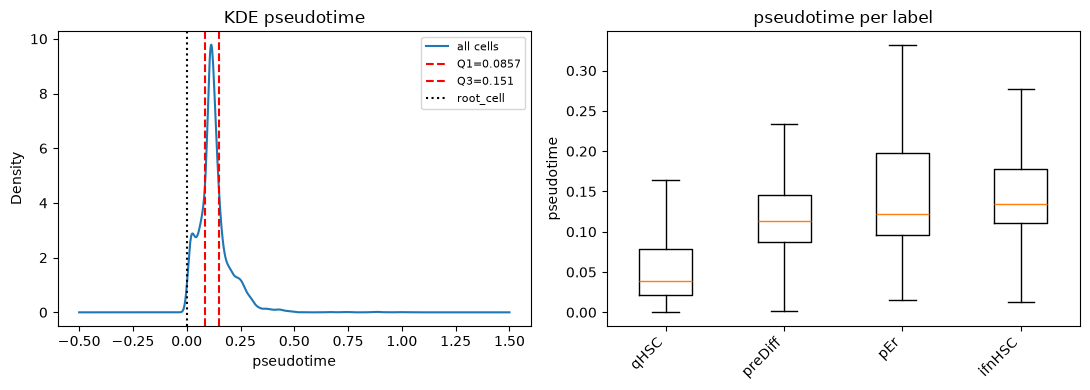

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

pt = adata.obs["pseudotime"].astype(float)
pt = pt[np.isfinite(pt)]
pt.plot.kde(ax=axes[0], label="all cells")
q1, q3 = float(pt.quantile(0.25)), float(pt.quantile(0.75))
axes[0].axvline(q1, color="red", ls="--", label=f"Q1={q1:.3g}")
axes[0].axvline(q3, color="red", ls="--", label=f"Q3={q3:.3g}")
if "root_cell" in adata.uns and adata.uns["root_cell"] in adata.obs_names:
    axes[0].axvline(
        float(adata.obs.loc[adata.uns["root_cell"], "pseudotime"]),
        color="black",
        ls=":",
        label="root_cell",
    )
axes[0].set_xlabel("pseudotime")
axes[0].set_title("KDE pseudotime")
axes[0].legend(fontsize=8)

order = (
    adata.obs.groupby("label", observed=True)["pseudotime"]
    .median()
    .sort_values()
    .index.astype(str)
    .tolist()
)
plot_df = adata.obs[["label", "pseudotime"]].copy()
plot_df["label"] = plot_df["label"].astype(str)
# boxen-like: boxplot ordered by median pt
data = [plot_df.loc[plot_df["label"] == lab, "pseudotime"].astype(float).to_numpy() for lab in order]
axes[1].boxplot(data, tick_labels=order, vert=True, showfliers=False)
axes[1].set_xticklabels(order, rotation=45, ha="right")
axes[1].set_ylabel("pseudotime")
axes[1].set_title("pseudotime per label")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "pseudotime_kde_box.png", dpi=150, bbox_inches="tight")
plt.show()


### Stream / subway — `plot_streamlike`

Reimplementacja layoutu STREAM (`plot_stream_sc` / `add_stream_sc_pos`) na kontrakcie §12.5 — bez `flat_tree` / EPG.


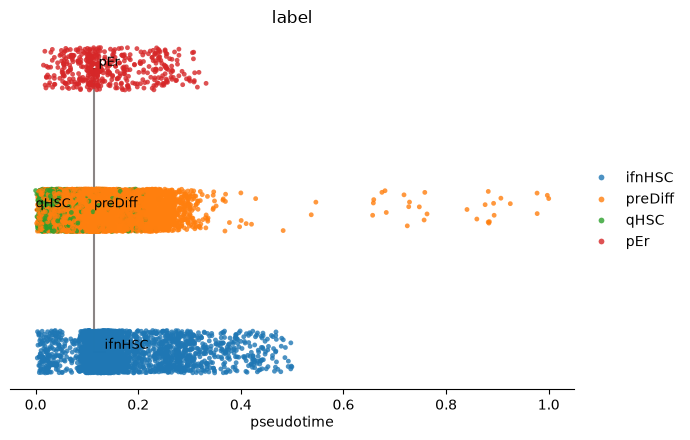

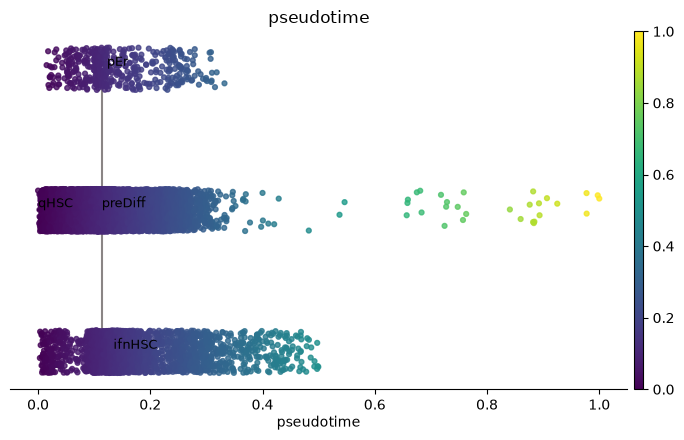

[<Figure size 700x450 with 1 Axes>, <Figure size 700x450 with 2 Axes>]

In [15]:
import sys
from pathlib import Path

_ROOT = Path.cwd()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from src.utils.plot_streamlike import plot_streamlike

plot_streamlike(
    adata,
    root=adata.uns.get("root_state"),
    color=["label", "pseudotime"],
    state_key="label",
    pt_key="pseudotime",
    edges=adata.uns.get("trajectory_edges"),
    show_graph=True,
    show_text=True,
    save_fig=True,
    fig_path=FIGURES_DIR,
    fig_format="png",
    show=True,
)


### Sanity: nasz `pseudotime` vs paper `paper_pseudotime` (jeśli dostępny)


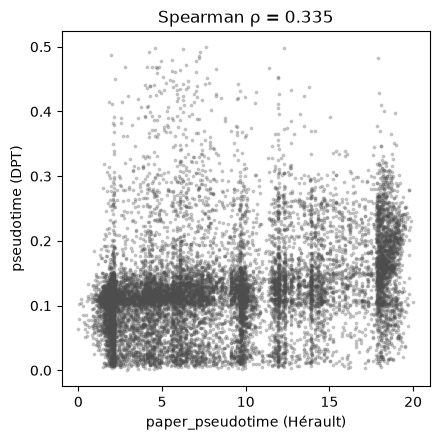

In [16]:
if "paper_pseudotime" in adata.obs and adata.obs["paper_pseudotime"].notna().any():
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    m = adata.obs["paper_pseudotime"].notna() & np.isfinite(adata.obs["pseudotime"])
    ax.scatter(
        adata.obs.loc[m, "paper_pseudotime"],
        adata.obs.loc[m, "pseudotime"],
        s=3,
        alpha=0.25,
        c="0.3",
    )
    ax.set_xlabel("paper_pseudotime (Hérault)")
    ax.set_ylabel("pseudotime (DPT)")
    rho = adata.obs.loc[m, ["paper_pseudotime", "pseudotime"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"Spearman ρ = {rho:.3f}")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "pseudotime_vs_paper.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("paper_pseudotime unavailable — skip")


### Save results

Wspólna końcówka (§12.6–12.8 w `docs/stream_trajectory_inference_skrot.md`):

1. `select_observations` — per `label` komórki z `pseudotime` w Q1–Q3 (bez `node` EPG)
2. `derive_bonesis_constraints` — łańcuch transientów + `bo.fixed` na terminalach (tylko stany z CSV)
3. zapis `results/{method}/` (`trajectory.h5ad`, CSV, `transition_constraints.{txt,json}`)

In [17]:
from pathlib import Path
import json

import networkx as nx

from src.utils.trajectory_graph import derive_trajectory_graph

METHOD = globals().get("METHOD", "paga_dpt")
RESULTS_DIR = Path("results") / METHOD
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = globals().get("FIGURES_DIR", RESULTS_DIR / "figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def select_observations(
    adata,
    *,
    pt_key: str = "pseudotime",
    label_key: str = "label",
) -> pd.Series:
    """Per fenotyp: komórki z pseudotime w [Q1, Q3] tego stanu (§12.6)."""
    if pt_key not in adata.obs:
        raise KeyError(f"Missing obs[{pt_key!r}] — run TI first")
    if label_key not in adata.obs:
        raise KeyError(f"Missing obs[{label_key!r}]")

    parts = []
    for state, idx in adata.obs.groupby(label_key, observed=True).groups.items():
        state = str(state)
        pt = adata.obs.loc[idx, pt_key].astype(float)
        pt = pt[np.isfinite(pt)]
        if pt.empty:
            continue
        q1, q3 = pt.quantile(0.25), pt.quantile(0.75)
        mid = pt[(pt >= q1) & (pt <= q3)]
        if mid.empty:
            continue
        parts.append(pd.Series(state, index=mid.index, name="observation"))

    if not parts:
        raise ValueError("select_observations: no cells survived Q1–Q3 filter")
    out = pd.concat(parts)
    # one label per cell if overlaps (shouldn't); keep first
    out = out[~out.index.duplicated(keep="first")]
    out.index.name = None
    return out


def derive_bonesis_constraints(
    adata,
    observations: pd.Series,
    *,
    method: str = METHOD,
    pt_key: str = "pseudotime",
    label_key: str = "label",
    terminal_states: list | None = None,
) -> dict:
    """Więzy BoNesis ze stanów obecnych w CSV (§12.7).

    Topologia (`transient_order`, który stan jest bezpośrednim "hubem" dla
    danego terminala) pochodzi z realnego grafu stanów
    (`derive_trajectory_graph` — PAGA `connectivities_tree`, nie z sortowania
    stanów po medianie pseudoczasu), żeby być spójna z wykresem
    flat-tree-like i `plot_streamlike`.
    """
    present = sorted(observations.astype(str).unique())
    terminals_prior = list(
        terminal_states
        if terminal_states is not None
        else adata.uns.get("terminal_states", [])
    )
    terminals = [s for s in terminals_prior if s in present]
    # also treat primed labels in CSV as terminals if prior list empty
    if not terminals:
        terminals = [s for s in present if s.startswith("p") and s[1:2].isupper()]

    root = str(adata.uns.get("root_state"))
    tree, root, edge_source = derive_trajectory_graph(
        adata,
        root=root,
        state_key=label_key,
        pt_key=pt_key,
        terminal_states=terminals,
    )
    sub = tree.subgraph([n for n in tree.nodes if n in present or n == root])

    non_terminal = [s for s in present if s not in terminals]
    depth = nx.shortest_path_length(sub, root) if root in sub else {}
    med = (
        adata.obs.loc[observations.index]
        .groupby(observations.rename("observation"), observed=True)[pt_key]
        .median()
        .astype(float)
    )
    # order by real tree depth from root first, median pt only as a tie-break
    transient_order = sorted(
        non_terminal,
        key=lambda s: (depth.get(s, len(present) + 1), float(med.get(s, np.inf))),
    )
    hub = transient_order[-1] if transient_order else None

    def _real_hub(terminal: str) -> str | None:
        """Terminal's actual tree predecessor when it's a known transient/root,
        else fall back to the global hub (keeps old behaviour for degenerate trees)."""
        preds = list(sub.predecessors(terminal)) if terminal in sub else []
        if preds and (preds[0] in transient_order or preds[0] == root):
            return preds[0]
        return hub

    bonesis_lines = []
    edges = []

    if len(transient_order) >= 2:
        chain = " >= ".join(f'~bo.obs("{s}")' for s in transient_order)
        bonesis_lines.append(chain)
        edges.extend(list(zip(transient_order[:-1], transient_order[1:])))

    for t in terminals:
        src = _real_hub(t)
        if src is None:
            continue
        bonesis_lines.append(f'~bo.obs("{src}") >= bo.fixed(~bo.obs("{t}"))')
        edges.append([src, t])

    supports_branching = len(terminals) >= 1 and (hub is not None or root in present)

    payload = {
        "method": method,
        "transient_chain": transient_order,
        "terminals": terminals,
        "hub": hub,
        "bonesis_lines": bonesis_lines,
        "edges": [list(e) for e in edges],
        "supports_branching": supports_branching,
        "states_in_csv": present,
        "edge_source": edge_source,
    }
    adata.uns["transient_order"] = transient_order
    adata.uns["trajectory_edges"] = payload["edges"]
    return payload


print("RESULTS_DIR =", RESULTS_DIR.resolve())
print("helpers: select_observations, derive_bonesis_constraints")


RESULTS_DIR = /home/jasiek/Dokumenty/ideas/scRNAseq-pipeline/results/paga_dpt
helpers: select_observations, derive_bonesis_constraints


#### 1. `select_observations` → CSV

In [18]:
observations = select_observations(adata, pt_key="pseudotime", label_key="label")
obs_csv = RESULTS_DIR / "pseudotime_inferred_observations.csv"
observations.to_frame().to_csv(obs_csv)

print(f"Wrote {obs_csv}  (n={len(observations)})")
print(observations.value_counts().to_string())
observations.head()

Wrote results/paga_dpt/pseudotime_inferred_observations.csv  (n=7048)
observation
preDiff    4518
ifnHSC     1646
qHSC        661
pEr         223


AAACGGGTCTTGTTTG-1_0    ifnHSC
ACATCAGTCATGCTCC-1_0    ifnHSC
ACCGTAACAGATCCAT-1_0    ifnHSC
ACGCCAGAGCTGCAAG-1_0    ifnHSC
AGGGAGTGTCCAAGTT-1_0    ifnHSC
Name: observation, dtype: object

#### 2. `derive_bonesis_constraints` → txt + json

In [19]:
constraints = derive_bonesis_constraints(
    adata,
    observations,
    method=METHOD,
    pt_key="pseudotime",
    label_key="label",
    terminal_states=list(adata.uns.get("terminal_states", [])),
)

txt_path = RESULTS_DIR / "transition_constraints.txt"
json_path = RESULTS_DIR / "transition_constraints.json"
txt_path.write_text("\n".join(constraints["bonesis_lines"]) + ("\n" if constraints["bonesis_lines"] else ""))
json_path.write_text(json.dumps(constraints, indent=2))

print(f"Wrote {txt_path}")
print(f"Wrote {json_path}")
print("transient_chain:", constraints["transient_chain"])
print("terminals:", constraints["terminals"], "| hub:", constraints["hub"])
print("--- bonesis_lines ---")
for line in constraints["bonesis_lines"]:
    print(line)
constraints

Wrote results/paga_dpt/transition_constraints.txt
Wrote results/paga_dpt/transition_constraints.json
transient_chain: ['qHSC', 'preDiff', 'ifnHSC']
terminals: ['pEr'] | hub: ifnHSC
--- bonesis_lines ---
~bo.obs("qHSC") >= ~bo.obs("preDiff") >= ~bo.obs("ifnHSC")
~bo.obs("preDiff") >= bo.fixed(~bo.obs("pEr"))


{'method': 'paga_dpt',
 'transient_chain': ['qHSC', 'preDiff', 'ifnHSC'],
 'terminals': ['pEr'],
 'hub': 'ifnHSC',
 'bonesis_lines': ['~bo.obs("qHSC") >= ~bo.obs("preDiff") >= ~bo.obs("ifnHSC")',
  '~bo.obs("preDiff") >= bo.fixed(~bo.obs("pEr"))'],
 'edges': [['qHSC', 'preDiff'], ['preDiff', 'ifnHSC'], ['preDiff', 'pEr']],
 'supports_branching': True,
 'states_in_csv': ['ifnHSC', 'pEr', 'preDiff', 'qHSC'],
 'edge_source': 'paga'}

#### 3. `trajectory.h5ad` (+ `X_plot`)

In [20]:
if "X_umap" in adata.obsm:
    adata.obsm["X_plot"] = np.asarray(adata.obsm["X_umap"])
elif "X_pca" in adata.obsm:
    adata.obsm["X_plot"] = np.asarray(adata.obsm["X_pca"])[:, :2]

adata.uns["method"] = METHOD

# Slim AnnData: contract slots only (skip full expression matrix)
_uns_keys = [
    "root_state",
    "terminal_states",
    "transient_states",
    "transient_order",
    "trajectory_edges",
    "root_cell",
    "iroot",
    "method",
    "ti_priors",
    "ti_priors_B",
    "paga",
]
_obsm_keys = [k for k in ("X_plot", "X_pca", "X_umap", "X_diffmap") if k in adata.obsm]
ad_ti = ad.AnnData(
    obs=adata.obs.copy(),
    obsm={k: np.asarray(adata.obsm[k]) for k in _obsm_keys},
)
ad_ti.uns.update({k: adata.uns[k] for k in _uns_keys if k in adata.uns})

h5ad_path = RESULTS_DIR / "trajectory.h5ad"
ad_ti.write_h5ad(h5ad_path)
print(f"Wrote {h5ad_path}")
print("slots:", {
    "pseudotime": "pseudotime" in ad_ti.obs,
    "branch": "branch" in ad_ti.obs,
    "root_state": ad_ti.uns.get("root_state"),
    "terminal_states": ad_ti.uns.get("terminal_states"),
    "transient_order": ad_ti.uns.get("transient_order"),
    "X_plot": "X_plot" in ad_ti.obsm,
})
sorted(p.name for p in RESULTS_DIR.iterdir())


Wrote results/paga_dpt/trajectory.h5ad
slots: {'pseudotime': True, 'branch': True, 'root_state': 'qHSC', 'terminal_states': ['pEr'], 'transient_order': ['qHSC', 'preDiff', 'ifnHSC'], 'X_plot': True}


['figures',
 'pseudotime_inferred_observations.csv',
 'trajectory.h5ad',
 'transition_constraints.json',
 'transition_constraints.txt']